# Getting Started with AI for Spatial Data: NYC 311 Service Requests

In this notebook you will use an open large language model (**Gemma 4**, run on a free Colab GPU with Hugging Face `transformers`) to analyse real **NYC 311 service requests**, and then ask *where* things happen.

| Part | What you do |
|---|---|
| 1. Data | Download a week of NYC 311 requests from NYC Open Data and explore them |
| 2. Baseline | Classify requests into themes with a simple keyword search |
| 3–4. LLM classification | Load Gemma 4 and classify with **constrained decoding** (the model can only answer with a valid label, and gives a confidence) |
| 5. Evaluation | Score keywords and prompts against the **official 311 complaint types**: accuracy, macro F1, Cohen's kappa, calibration |
| 6. Next steps | Follow-up exercises |

**Before you start**
1. `Runtime → Change runtime type → T4 GPU → Save`.
2. Optional but recommended: add your Hugging Face token as a Colab secret named `HF_TOKEN` (🔑 icon in the left sidebar, turn on *Notebook access*). It is required only if you switch to a gated model such as Gemma 3.
3. Run the cells in order with **Shift + Enter**.

No GPU? Set `USE_LLM = False` in the settings cell. Every section still runs, using offline stand-ins for the model.

In [1]:
# Libraries that are not pre-installed in Colab (about 1 minute)
%pip install -q -U transformers accelerate
# Only needed if you set LOAD_IN_4BIT = True below
# %pip install -q bitsandbytes

## Settings
Change these before running the rest of the notebook.

In [2]:
# ---- Model --------------------------------------------------------------------------
USE_LLM       = True                       # False = run every section without a model (no GPU needed)
MODEL_NAME    = "google/gemma-4-E2B-it"    # fits a free T4 GPU in bfloat16 (~10 GB)
# MODEL_NAME  = "google/gemma-4-E4B-it"    # stronger; on a T4 set LOAD_IN_4BIT = True (and install bitsandbytes)
# MODEL_NAME  = "google/gemma-3-4b-it"     # previous workshop model (gated: accept the licence + HF_TOKEN)
LOAD_IN_4BIT  = False
FAST_FP16     = False                      # True = float16 (faster on a T4) but can give wrong answers with Gemma; keep False
CALIBRATE     = True                       # remove the model's built-in preference for some answer letters
BATCH_SIZE    = 16                         # lowered automatically if the GPU runs out of memory

# ---- Data ---------------------------------------------------------------------------
START_DATE    = "2026-09-01"               # one week of 311 requests (inclusive start)
END_DATE      = "2026-09-08"               # exclusive end
N_REQUESTS    = 1000                       # random sample analysed in this notebook (2000+ after the workshop)
SEED          = 42

# ---- Where files are saved (your Google Drive when in Colab) -----------------------
DRIVE_FOLDER  = "GenAI_Spatial_Workshop"

## Connect to Google Drive and Hugging Face
When asked, click **Connect to Google Drive** and allow access. Downloaded data and results are saved in `MyDrive/Colab Notebooks/GenAI_Spatial_Workshop`, so you can re-run the notebook later without downloading again.

In [3]:
import os
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/") / DRIVE_FOLDER
    try:
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        print("No HF_TOKEN secret found. That is fine for Gemma 4; gated models (e.g. Gemma 3) need it.")
else:
    DATA_DIR = Path(os.environ.get("WORKSHOP_DATA_DIR", "workshop_data"))

DATA_DIR.mkdir(parents=True, exist_ok=True)
if os.environ.get("HF_TOKEN"):
    from huggingface_hub import login
    login(os.environ["HF_TOKEN"])
print("Files will be saved in:", DATA_DIR)

Mounted at /content/drive


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Files will be saved in: /content/drive/MyDrive/Colab Notebooks/GenAI_Spatial_Workshop


In [4]:
import json, re, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
import requests
from IPython.display import display, Markdown
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
rng = np.random.default_rng(SEED)

# Part 1 — Data: NYC 311 service requests

[NYC 311](https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2010-to-Present/erm2-nwe9) is the city's non-emergency line. Every request has a location, an official **complaint type** chosen when it is filed, a short **descriptor**, a **location type**, and a status.

The cell below downloads one week through the NYC Open Data (Socrata) API and caches it on your Drive. If the API is unavailable, put the snapshot CSV from the workshop Drive folder (`nyc311_snapshot.csv`) in `MyDrive/Colab Notebooks/GenAI_Spatial_Workshop`.

In [5]:
API_URL = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
COLUMNS = ["unique_key", "created_date", "agency", "complaint_type", "descriptor", "location_type",
           "incident_zip", "borough", "latitude", "longitude", "status", "community_board"]          # street addresses are deliberately NOT downloaded (privacy)

CACHE_FILE = DATA_DIR / f"nyc311_{START_DATE}_{END_DATE}.csv"
SNAPSHOT_FILE = DATA_DIR / "nyc311_snapshot.csv"


def download_311(start, end, page_size=50_000, max_rows=150_000):
    where = (f"created_date >= '{start}T00:00:00' AND created_date < '{end}T00:00:00' "
             "AND latitude IS NOT NULL")
    frames, offset = [], 0
    while offset < max_rows:
        params = {"$select": ",".join(COLUMNS), "$where": where, "$order": "unique_key",
                  "$limit": page_size, "$offset": offset}
        r = requests.get(API_URL, params=params, timeout=120)
        r.raise_for_status()
        page = pd.DataFrame(r.json())
        print(f"  downloaded {offset + len(page):,} rows")
        if page.empty:
            break
        frames.append(page)
        if len(page) < page_size:
            break
        offset += page_size
    return pd.concat(frames, ignore_index=True)


if CACHE_FILE.exists():
    raw = pd.read_csv(CACHE_FILE, dtype=str)
    print("Loaded cached file:", CACHE_FILE)
else:
    try:
        print("Downloading 311 requests from NYC Open Data ...")
        raw = download_311(START_DATE, END_DATE)
        raw.to_csv(CACHE_FILE, index=False)
        print("Saved to", CACHE_FILE)
    except Exception as err:
        print("Download failed:", err)
        if not SNAPSHOT_FILE.exists():
            raise FileNotFoundError(f"Put nyc311_snapshot.csv from the workshop Drive folder in {DATA_DIR}")
        raw = pd.read_csv(SNAPSHOT_FILE, dtype=str)
        print("Loaded snapshot:", SNAPSHOT_FILE)

print(f"{len(raw):,} requests between {START_DATE} and {END_DATE}")

  downloaded 50,000 rows
  downloaded 70,532 rows
Saved to /content/drive/MyDrive/Colab Notebooks/GenAI_Spatial_Workshop/nyc311_2026-09-01_2026-09-08.csv
70,532 requests between 2026-09-01 and 2026-09-08


### Prepare the data
* Keep requests with valid NYC coordinates and take a reproducible random sample.
* Build the **text the model will read**: the descriptor and the location type (e.g. *"Loud Music/Party; location: Residential Building/House"*). The model never sees the official complaint type.
* Map each official complaint type to one of seven **themes**. These official labels are our ground truth for evaluation.

In [6]:
THEMES = ["Noise", "Housing & Buildings", "Streets, Traffic & Parking", "Sanitation & Cleanliness",
          "Trees, Parks & Environment", "Homelessness & Public Safety", "Business & Consumer"]

# Official complaint type -> theme (case-insensitive). Anything not listed falls back to the agency.
THEME_MAP = {
    # Housing & Buildings (HPD, DOB)
    **{k: "Housing & Buildings" for k in [
        "unsanitary condition", "paint/plaster", "plumbing", "water leak", "door/window", "general",
        "heat/hot water", "electric", "flooring/stairs", "appliance", "safety", "elevator", "boilers",
        "general construction/plumbing", "building/use", "lead", "indoor air quality", "outside building",
        "emergency response team (ert)", "construction safety enforcement", "scaffold safety",
        "non-residential heat", "electrical", "mold"]},
    # Streets, Traffic & Parking (NYPD parking, DOT, TLC)
    **{k: "Streets, Traffic & Parking" for k in [
        "illegal parking", "blocked driveway", "street condition", "abandoned vehicle", "derelict vehicles",
        "street light condition", "traffic signal condition", "sidewalk condition", "curb condition",
        "for hire vehicle complaint", "for hire vehicle report", "taxi complaint", "taxi report",
        "highway condition", "traffic", "street sign - missing", "street sign - damaged",
        "street sign - dangling", "bus stop shelter complaint", "e-scooter", "bike/roller/skate chronic",
        "bridge condition", "broken parking meter", "obstruction", "dot sidewalk"]},
    # Sanitation & Cleanliness (DSNY, rodents)
    **{k: "Sanitation & Cleanliness" for k in [
        "dirty condition", "illegal dumping", "missed collection", "residential disposal complaint",
        "commercial disposal complaint", "graffiti", "dead animal", "rodent", "litter basket request",
        "litter basket complaint", "dumpster complaint", "street sweeping complaint", "illegal posting",
        "unsanitary animal pvt property", "sanitation worker or vehicle complaint", "derelict bicycle"]},
    # Trees, Parks & Environment (DPR, DEP)
    **{k: "Trees, Parks & Environment" for k in [
        "damaged tree", "overgrown tree/branches", "dead/dying tree", "illegal tree damage",
        "root/sewer/sidewalk condition", "new tree request", "maintenance or facility", "animal in a park",
        "violation of park rules", "water maintenance", "sewer maintenance", "water system", "sewer",
        "air quality", "standing water", "mosquitoes", "industrial waste", "special natural area district (snad)",
        "water quality", "hazardous materials", "asbestos", "smoking or vaping"]},
    # Homelessness & Public Safety (DHS, NYPD quality of life)
    **{k: "Homelessness & Public Safety" for k in [
        "encampment", "homeless person assistance", "non-emergency police matter", "panhandling",
        "drug activity", "drinking", "illegal fireworks", "animal-abuse", "urinating in public",
        "illegal animal kept as pet", "disorderly youth", "real time enforcement", "lost property",
        "homeless street condition", "posting advertisement"]},
    # Business & Consumer (DCWP, DOHMH food, vendors)
    **{k: "Business & Consumer" for k in [
        "consumer complaint", "vendor enforcement", "food establishment", "outdoor dining", "day care",
        "cannabis retailer", "food poisoning", "mobile food vendor", "tobacco or non-tobacco sale",
        "commercial disposal complaint", "dcwp: price gouging"]},
}
AGENCY_FALLBACK = {"HPD": "Housing & Buildings", "DOB": "Housing & Buildings", "DOT": "Streets, Traffic & Parking",
                   "TLC": "Streets, Traffic & Parking", "DSNY": "Sanitation & Cleanliness",
                   "DPR": "Trees, Parks & Environment", "DEP": "Trees, Parks & Environment",
                   "DHS": "Homelessness & Public Safety", "DCWP": "Business & Consumer"}


def official_theme(row):
    ct = str(row["complaint_type"]).strip().lower()
    if ct.startswith("noise"):
        return "Noise"
    return THEME_MAP.get(ct) or AGENCY_FALLBACK.get(str(row["agency"]), "Other")


df = raw.copy()
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
df = df[df["latitude"].between(40.49, 40.92) & df["longitude"].between(-74.27, -73.68)]   # NYC bounding box
df = df.drop_duplicates("unique_key")
df = df.sample(n=min(N_REQUESTS, len(df)), random_state=SEED).reset_index(drop=True)

df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
df["hour"] = df["created_date"].dt.hour
df["time_of_day"] = pd.cut(df["hour"], [-1, 5, 11, 17, 23], labels=["night", "morning", "afternoon", "evening"]).astype(str)
for col in ["descriptor", "location_type", "borough"]:
    df[col] = df[col].fillna("").astype(str).str.strip()
df["text"] = (df["descriptor"] + np.where(df["location_type"] != "", "; location: " + df["location_type"], ""))
df["official_theme"] = df.apply(official_theme, axis=1)

print(f"Sample: {len(df):,} requests")
print(f"Requests whose complaint type is not in the theme map ('Other'): {(df.official_theme == 'Other').sum()}")
display(df[["created_date", "agency", "complaint_type", "text", "borough", "official_theme"]].head(10))

Sample: 1,000 requests
Requests whose complaint type is not in the theme map ('Other'): 6


,created_date,agency,complaint_type,text,borough,official_theme
0,2026-09-02 08:38:07,DSNY,Illegal Dumping,Removal Request; location: Sidewalk,QUEENS,Sanitation & Cleanliness
1,2026-09-05 22:17:53,NYPD,Noise - Street/Sidewalk,Loud Music/Party; location: Street/Sidewalk,BRONX,Noise
2,2026-09-05 04:14:02,NYPD,Noise - Residential,Loud Music/Party; location: Residential Building/House,BROOKLYN,Noise
3,2026-09-05 00:00:32,DEP,Water Maintenance,Fire Hydrant Running; location: Sidewalk,QUEENS,"Trees, Parks & Environment"
4,2026-09-02 11:22:14,HPD,PAINT/PLASTER,WALL; location: RESIDENTIAL BUILDING,MANHATTAN,Housing & Buildings
5,2026-09-06 18:27:11,NYPD,Illegal Parking,Double Parked Blocking Traffic; location: Street/Sidewalk,BRONX,"Streets, Traffic & Parking"
6,2026-09-05 12:52:56,DOB,General Construction/Plumbing,Building Permit - None,BRONX,Housing & Buildings
7,2026-09-07 01:18:11,NYPD,Noise - Park,Loud Music/Party; location: Park/Playground,BROOKLYN,Noise
8,2026-09-06 22:47:47,NYPD,Noise - Street/Sidewalk,Loud Music/Party; location: Street/Sidewalk,BRONX,Noise
9,2026-09-03 20:57:55,NYPD,Illegal Parking,Commercial Overnight Parking; location: Street/Sidewalk,STATEN ISLAND,"Streets, Traffic & Parking"


### Explore the data

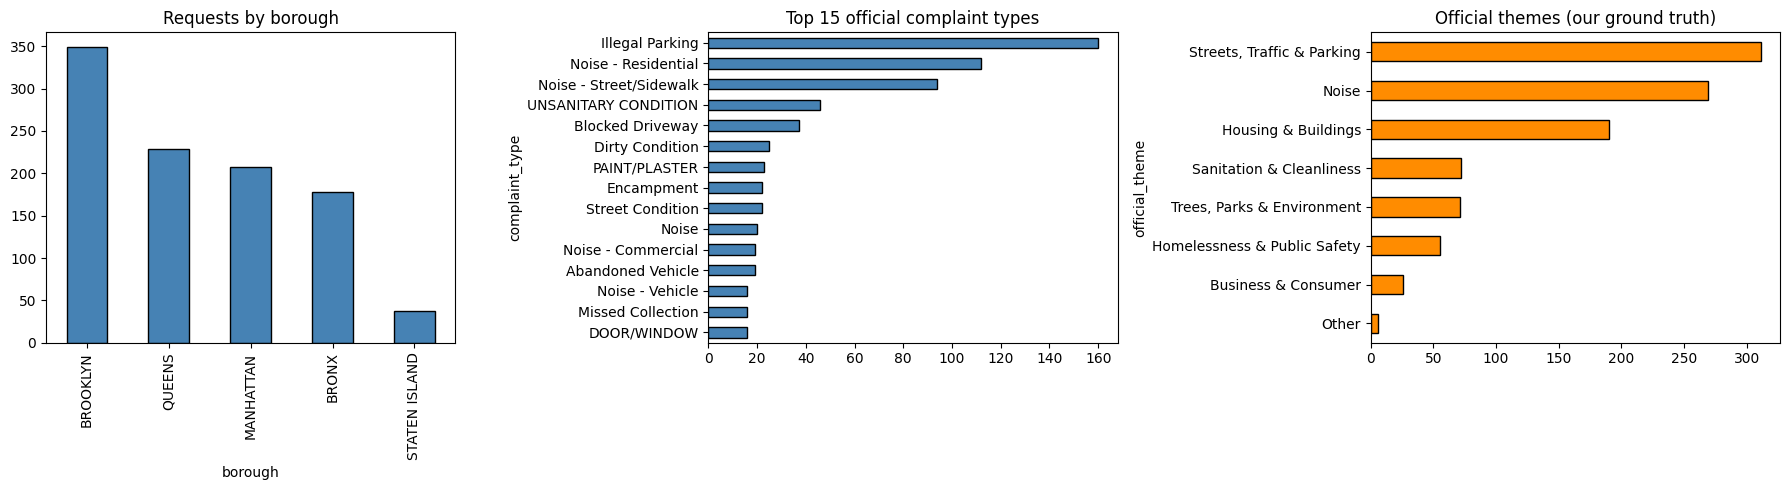

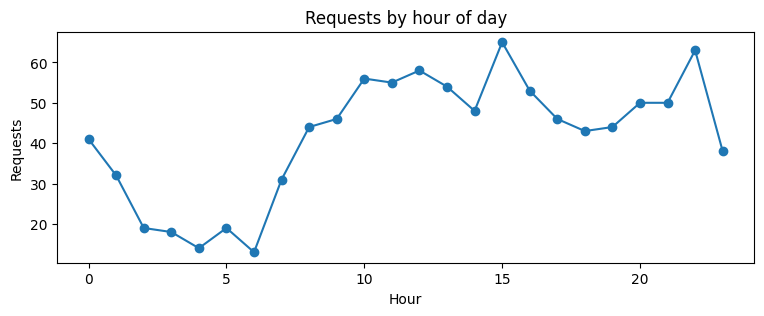

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df["borough"].replace("", "UNSPECIFIED").value_counts().plot.bar(ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Requests by borough")
df["complaint_type"].value_counts().head(15).sort_values().plot.barh(ax=axes[1], color="steelblue", edgecolor="black")
axes[1].set_title("Top 15 official complaint types")
df["official_theme"].value_counts().sort_values().plot.barh(ax=axes[2], color="darkorange", edgecolor="black")
axes[2].set_title("Official themes (our ground truth)")
plt.tight_layout(); plt.show()

ax = df.groupby("hour").size().plot(figsize=(9, 3), marker="o", title="Requests by hour of day")
ax.set_xlabel("Hour"); ax.set_ylabel("Requests"); plt.show()

In [8]:
NYC_CENTER = [40.7128, -73.95]
m = folium.Map(location=NYC_CENTER, zoom_start=11, tiles="Esri.WorldImagery")
cluster = MarkerCluster().add_to(m)
for _, r in df.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=4, color="cadetblue", fill=True, fill_opacity=0.7,
                        popup=folium.Popup(f"<b>{r.complaint_type}</b><br>{r.text}<br>{r.borough}", max_width=300)
                        ).add_to(cluster)
m

# Part 2 — Baseline: keyword search
A transparent rule-based classifier. It is fast and cheap but brittle: it only knows the words we give it.

In [9]:
KEYWORDS = {
    "Noise": ["noise", "loud", "music", "party", "banging", "barking", "horn", "alarm", "talking"],
    "Housing & Buildings": ["heat", "hot water", "mold", "leak", "plumbing", "paint", "plaster", "elevator",
                            "window", "door", "stairs", "electric", "appliance", "boiler", "lead", "building",
                            "ceiling", "bathroom", "kitchen", "residential building"],
    "Streets, Traffic & Parking": ["parking", "driveway", "hydrant", "pothole", "traffic", "signal", "street light",
                                   "vehicle", "car", "sidewalk", "curb", "sign", "taxi", "bus", "highway", "scooter"],
    "Sanitation & Cleanliness": ["trash", "garbage", "litter", "dumping", "collection", "recycling", "rat", "mouse",
                                 "rodent", "dirty", "graffiti", "dead animal", "sweeping", "basket", "removal"],
    "Trees, Parks & Environment": ["tree", "branch", "park", "sewer", "water main", "hydrant flushing", "catch basin",
                                   "air", "odor", "smoke", "mosquito", "standing water", "playground", "dog"],
    "Homelessness & Public Safety": ["homeless", "encampment", "panhandling", "drug", "drinking", "fireworks",
                                     "abuse", "police", "urinating", "person", "chronic"],
    "Business & Consumer": ["vendor", "store", "restaurant", "food", "consumer", "dining", "business", "price",
                            "day care", "cannabis", "license"],
}


def keyword_classifier(text: str) -> str:
    t = text.lower()
    scores = {theme: sum(k in t for k in kws) for theme, kws in KEYWORDS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "Other"


df["keyword_theme"] = df["text"].apply(keyword_classifier)
print("No keyword matched:", (df["keyword_theme"] == "Other").sum(), "requests")
df[["text", "keyword_theme", "official_theme"]].head(10)

No keyword matched: 32 requests


,text,keyword_theme,official_theme
0,Removal Request; location: Sidewalk,"Streets, Traffic & Parking",Sanitation & Cleanliness
1,Loud Music/Party; location: Street/Sidewalk,Noise,Noise
2,Loud Music/Party; location: Residential Building/House,Noise,Noise
3,Fire Hydrant Running; location: Sidewalk,"Streets, Traffic & Parking","Trees, Parks & Environment"
4,WALL; location: RESIDENTIAL BUILDING,Housing & Buildings,Housing & Buildings
5,Double Parked Blocking Traffic; location: Street/Sidewalk,"Streets, Traffic & Parking","Streets, Traffic & Parking"
6,Building Permit - None,Housing & Buildings,Housing & Buildings
7,Loud Music/Party; location: Park/Playground,Noise,Noise
8,Loud Music/Party; location: Street/Sidewalk,Noise,Noise
9,Commercial Overnight Parking; location: Street/Sidewalk,"Streets, Traffic & Parking","Streets, Traffic & Parking"


# Part 3 — Load Gemma 4 from Hugging Face
The first run downloads the model weights (a few GB, 2–5 minutes). `USE_LLM = False` skips this.

In [10]:
import torch
from transformers import AutoProcessor

model, processor, tokenizer = None, None, None


def load_model(name):
    import transformers
    kwargs = {"device_map": "auto"}
    if LOAD_IN_4BIT:
        from transformers import BitsAndBytesConfig
        kwargs["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.bfloat16)
    else:
        kwargs["dtype"] = DTYPE
    try:
        proc = AutoProcessor.from_pretrained(name)
    except Exception:                      # text-only models have no multimodal processor
        from transformers import AutoTokenizer
        proc = AutoTokenizer.from_pretrained(name)
    last_err = None
    for cls_name in ["AutoModelForMultimodalLM", "AutoModelForImageTextToText", "AutoModelForCausalLM"]:
        cls = getattr(transformers, cls_name, None)
        if cls is None:
            continue
        try:
            mdl = cls.from_pretrained(name, **kwargs)
            print(f"Loaded {name} with {cls_name}")
            return mdl.eval(), proc
        except (ValueError, KeyError) as err:   # this class does not support the model; try the next one
            last_err = err
    raise RuntimeError(f"Could not load {name}: {last_err}")


def pick_dtype():
    if not torch.cuda.is_available():
        return torch.float32
    # T4 and other pre-Ampere GPUs (compute capability < 8) have no fast bfloat16 support
    old_gpu = torch.cuda.get_device_capability(0)[0] < 8
    return torch.float16 if (FAST_FP16 and old_gpu) else torch.bfloat16


@torch.no_grad()
def numerically_ok(mdl, tok):
    # float16 can overflow in some models: check that a test prompt gives finite logits
    enc = tok(["Classify this request: Loud Music/Party; location: Street/Sidewalk. Answer with a letter."],
              return_tensors="pt").to(mdl.device)
    return bool(torch.isfinite(mdl(**enc).logits.float()).all())


if USE_LLM:
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none – switch to a T4 runtime")
    DTYPE = pick_dtype()
    model, processor = load_model(MODEL_NAME)
    tokenizer = getattr(processor, "tokenizer", processor)
    if DTYPE == torch.float16 and not LOAD_IN_4BIT and not numerically_ok(model, tokenizer):
        print("float16 gave invalid numbers for this model; reloading in bfloat16 (slower but safe)")
        del model; torch.cuda.empty_cache()
        DTYPE = torch.bfloat16
        model, processor = load_model(MODEL_NAME)
        tokenizer = getattr(processor, "tokenizer", processor)
    print("Precision:", str(DTYPE).replace("torch.", ""))
    tokenizer.padding_side = "left"            # required for batched generation
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    if torch.cuda.is_available():
        print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
else:
    print("USE_LLM = False: the notebook will use offline stand-ins instead of the model.")

GPU: Tesla T4


processor_config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1951 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

Loaded google/gemma-4-E2B-it with AutoModelForMultimodalLM
Precision: bfloat16
GPU memory in use: 10.2 GB


### Two ways to get an answer from the model
* **`generate()`** — the model writes free text. Flexible, but the reply has to be parsed and can be anything.
* **`score_choices()`** — *constrained decoding*. We list the options as letters (A, B, C, …) and read the model's probability for each letter at the first answer position. The answer is **always a valid label**, it needs **one forward pass** instead of many generated tokens (fast), and the probability is a **confidence** we can check.

In [11]:
def render(prompt: str, system: str = None) -> str:
    # Wrap a prompt in the model's chat template (thinking mode off)
    msgs = []
    if system:
        msgs.append({"role": "system", "content": [{"type": "text", "text": system}]})
    msgs.append({"role": "user", "content": [{"type": "text", "text": prompt}]})
    try:
        return processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    except Exception:   # text-only tokenizers expect plain-string content
        msgs = [{"role": m["role"], "content": m["content"][0]["text"]} for m in msgs]
        return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


def _encode(texts):
    enc = tokenizer(texts, return_tensors="pt", padding=True, add_special_tokens=False)
    return {k: v.to(model.device) for k, v in enc.items()}


def _letter_ids(n):
    # Token ids for "A", "B", ... (with and without a leading space)
    ids = []
    for letter in "ABCDEFGHIJ"[:n]:
        variants = set()
        for s in (letter, " " + letter):
            toks = tokenizer.encode(s, add_special_tokens=False)
            if toks:
                variants.add(toks[-1])
        ids.append(sorted(variants))
    return ids


def run_batches(n_items, order, step, batch_size, desc):
    # Run step(idx) over batches; if the GPU runs out of memory, halve the batch size and retry
    start, bar = 0, tqdm(total=n_items, desc=desc)
    while start < n_items:
        idx = order[start:start + batch_size]
        try:
            step(idx)
        except torch.cuda.OutOfMemoryError:
            if batch_size == 1:
                raise
            torch.cuda.empty_cache()
            batch_size = max(1, batch_size // 2)
            print(f"GPU memory full: lowering the batch size to {batch_size}")
            continue
        start += len(idx)
        bar.update(len(idx))
    bar.close()


def _last_logits(enc):
    # Only compute the logits for the last position: the full (batch x tokens x 262k vocabulary)
    # tensor would need several GB of GPU memory
    try:
        return model(**enc, logits_to_keep=1).logits[:, -1, :].float()
    except TypeError:   # older models without logits_to_keep
        return model(**enc).logits[:, -1, :].float()


ANSWER_PREFIX = "Answer:"


@torch.no_grad()
def score_choices(prompts, n_choices, batch_size=BATCH_SIZE, desc="Scoring"):
    # Probability of each answer letter for every prompt -> array (n_prompts, n_choices)
    letter_ids = _letter_ids(n_choices)
    out = np.zeros((len(prompts), n_choices))
    order = np.argsort([len(p) for p in prompts])          # similar lengths together = less padding

    def step(idx):
        # Start the model's reply with "Answer:" so the very next token must be the letter
        logits = _last_logits(_encode([render(prompts[i]) + ANSWER_PREFIX for i in idx]))
        letter_logits = torch.stack([torch.logsumexp(logits[:, ids], dim=-1) for ids in letter_ids], dim=-1)
        out[idx] = torch.softmax(letter_logits, dim=-1).cpu().numpy()

    run_batches(len(prompts), order, step, batch_size, desc)

    # Safety net: a numerical overflow gives NaN probabilities. Re-score those prompts one at a time.
    bad = np.where(~np.isfinite(out).all(axis=1))[0]
    if len(bad):
        print(f"{len(bad)} prompts gave invalid numbers; re-scoring them one at a time")
        run_batches(len(bad), bad, step, 1, desc + " (retry)")
        still = (~np.isfinite(out[bad]).all(axis=1)).sum()
        if still:
            print(f"WARNING: {still} prompts still invalid; they are labelled 'Other'. "
                  "Use bfloat16 (FAST_FP16 = False) and restart the session.")
    return out


THOUGHT_RE = re.compile(r"<\|?channel\|?>.*?<channel\|>", re.S)


@torch.no_grad()
def generate(prompts, max_new_tokens=64, batch_size=BATCH_SIZE, system=None, desc="Generating", stop=None):
    # Free-text replies (greedy decoding, so results are reproducible)
    replies = [None] * len(prompts)
    order = np.argsort([len(p) for p in prompts])
    args = dict(max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id)

    def step(idx):
        enc = _encode([render(prompts[i], system) for i in idx])
        try:   # stop early at a stop string (e.g. the closing "}" of a JSON object) to save time
            gen = model.generate(**enc, **args, **({"stop_strings": stop, "tokenizer": tokenizer} if stop else {}))
        except ValueError:
            gen = model.generate(**enc, **args)
        new_tokens = gen[:, enc["input_ids"].shape[1]:]
        for i, text in zip(idx, tokenizer.batch_decode(new_tokens, skip_special_tokens=True)):
            replies[i] = THOUGHT_RE.sub("", text).strip()

    run_batches(len(prompts), order, step, batch_size, desc)
    return replies


if USE_LLM:
    print(generate(["In one sentence, what is NYC 311?"], max_new_tokens=40)[0])

Generating:   0%|          | 0/1 [00:00<?, ?it/s]

NYC 311 is a non-emergency service that allows residents to report city issues, request services, and find information about city services.


### Sanity check: does the scoring work with this model?
Seven obvious requests, one per theme. Constrained scoring should get at least 6 of 7 right. If it does not, **stop here**: Part 4 would give near-random labels. Try `FAST_FP16 = False`, or a different `MODEL_NAME`, then restart and rerun.

In [12]:
CHECK = [("Loud music and a party next door; location: Residential Building/House", "Noise"),
         ("No heat or hot water in apartment; location: RESIDENTIAL BUILDING", "Housing & Buildings"),
         ("Car parked blocking a fire hydrant; location: Street/Sidewalk", "Streets, Traffic & Parking"),
         ("Overflowing trash on the sidewalk; location: Sidewalk", "Sanitation & Cleanliness"),
         ("Tree branch has fallen down; location: Street", "Trees, Parks & Environment"),
         ("Drug activity on the corner; location: Street/Sidewalk", "Homelessness & Public Safety"),
         ("Food vendor without a licence; location: Street", "Business & Consumer")]
check_options = "\n".join(f"{l}) {t}" for l, t in zip("ABCDEFG", THEMES))
check_prompts = [f"Classify this NYC 311 service request into one theme.\n{check_options}\n\n"
                 f"Request: \"{t}\"\nAnswer with a single letter." for t, _ in CHECK]
if USE_LLM:
    probs = score_choices(check_prompts, len(THEMES), desc="Sanity check")
    replies = generate(check_prompts, max_new_tokens=12, desc="Free replies")
    rows = [{"request": t, "expected": exp, "scored": THEMES[p.argmax()], "confidence": round(p.max(), 2),
             "free_reply": r} for (t, exp), p, r in zip(CHECK, probs, replies)]
    check = pd.DataFrame(rows)
    display(check)
    n_ok = (check.scored == check.expected).sum()
    if n_ok >= 6:
        print(f"OK: {n_ok}/7 correct. Scoring works with {MODEL_NAME}.")
    else:
        print(f"WARNING: only {n_ok}/7 correct. Look at free_reply: does the model answer with a letter? "
              "Fix this before running Part 4.")

Sanity check:   0%|          | 0/7 [00:00<?, ?it/s]

Free replies:   0%|          | 0/7 [00:00<?, ?it/s]

,request,expected,scored,confidence,free_reply
0,Loud music and a party next door; location: Residential Building/House,Noise,Noise,1.0,A
1,No heat or hot water in apartment; location: RESIDENTIAL BUILDING,Housing & Buildings,Housing & Buildings,1.0,B
2,Car parked blocking a fire hydrant; location: Street/Sidewalk,"Streets, Traffic & Parking","Streets, Traffic & Parking",1.0,C
3,Overflowing trash on the sidewalk; location: Sidewalk,Sanitation & Cleanliness,Sanitation & Cleanliness,1.0,D
4,Tree branch has fallen down; location: Street,"Trees, Parks & Environment","Trees, Parks & Environment",1.0,E
5,Drug activity on the corner; location: Street/Sidewalk,Homelessness & Public Safety,Homelessness & Public Safety,1.0,C
6,Food vendor without a licence; location: Street,Business & Consumer,Business & Consumer,1.0,G


OK: 7/7 correct. Scoring works with google/gemma-4-E2B-it.


# Part 4 — Prompt design for classification
Five prompt strategies (four run by default), all scored with constrained decoding. `{options}` becomes the lettered list of themes.

| Prompt | Strategy |
|---|---|
| `P1_zero_shot` | Plain instruction |
| `P2_definitions` | Adds a one-line definition of every theme |
| `P3_few_shot` | Adds 14 real examples of easily confused requests |
| `P4_geo_context` | Adds the borough and time of day as spatial–temporal context |
| `P5_retrieval` | Adds the 8 most similar *past* requests with their correct themes (retrieval-augmented few-shot) |
| `ENSEMBLE` | Averages the probabilities of P2, P3 and P5 |

`P4_geo_context` is defined but **not run by default** to save time (it alone takes about 8 minutes on a T4). Add it to `RUN_PROMPTS` if you have time.

The definitions follow the same rules as the official theme map, so the model is told exactly where the boundaries are (e.g. pests *inside* an apartment are Housing; rats on the street are Sanitation). `P5_retrieval` looks up similar requests from the rest of the week, which are **not** in the evaluation sample, so it is a fair test. `kNN_vote` uses those neighbours without any LLM, as a check that the model adds value.

**Memory:** only the logits for the answer position are computed (the full vocabulary for every token would need several GB), and if the GPU still runs out of memory the batch size is halved automatically.

**Speed tricks used here:** many requests share the same description, so each *unique* prompt is scored only once, and answers are cached on Drive. To save more time, remove prompts from `RUN_PROMPTS` (in the prompts cell) or lower `N_REQUESTS` in the settings cell.

In [13]:
LETTERS = "ABCDEFG"
OPTIONS = "\n".join(f"{l}) {t}" for l, t in zip(LETTERS, THEMES))

# Definitions that follow the same rules as the official theme map in Part 1
DEFINITIONS = "\n".join(f"{l}) {t}: {d}" for l, t, d in zip(LETTERS, THEMES, [
    "any noise: music, parties, banging, loud talking, construction noise, engines, horns, alarms, barking dogs",
    "problems in or with a building: heat/hot water, leaks, plumbing, mold, paint/plaster, pests or garbage "
    "inside residential buildings, appliances, electrical, floors/stairs, doors/windows, elevators, boilers, "
    "lead, illegal conversions or building use, after-hours construction work",
    "vehicles and the roadway: illegal or double parking, blocked hydrant/driveway/sidewalk, abandoned or "
    "derelict vehicles, potholes, cave-ins, broken sidewalks or curbs, traffic signals, street lights, street "
    "signs, taxis and for-hire vehicles, e-scooters, bus shelters, obstructions",
    "trash and dirt in public space: dirty sidewalks or lots, missed collection, illegal dumping, removal "
    "requests, overflowing litter baskets, dumpsters, graffiti, illegal posters, rat sightings, dead animals",
    "street trees (damaged, fallen, dead, overgrown, roots), park facilities and park rules, animals in parks, "
    "water mains, hydrants, sewers and catch basins, air quality, odors, smoking, standing water, mosquitoes",
    "homeless person assistance (chronic / non-chronic), encampments, panhandling, drug activity, public "
    "drinking or urinating, fireworks, animal abuse, non-emergency police matters, lost property",
    "businesses: stores, restaurants and food establishments, street vendors, outdoor dining, consumer "
    "complaints, day care, cannabis and tobacco retailers"]))

# Hand-picked examples covering the most confusable cases (real 311 descriptors)
FEW_SHOT = "\n".join(f'Request: "{t}" -> {l}' for t, l in [
    ("Banging/Pounding; location: Residential Building/House", "A"),
    ("Engine Idling; location: Street/Sidewalk", "A"),
    ("PESTS; location: RESIDENTIAL BUILDING", "B"),
    ("Illegal Conversion Of Residential Building/Space", "B"),
    ("Posted Parking Sign Violation; location: Street/Sidewalk", "C"),
    ("No Access; location: Street/Sidewalk", "C"),
    ("With License Plate; location: Street/Sidewalk", "C"),
    ("Removal Request; location: Sidewalk", "D"),
    ("Trash; location: Street", "D"),
    ("Branch Cracked and Will Fall; location: Street", "E"),
    ("Structure - Outdoors; location: Park", "E"),
    ("Non-Chronic; location: Subway", "F"),
    ("Food Vendor; location: Street", "G"),
    ("Rodents/Insects/Garbage; location: Restaurant/Bar/Deli/Bakery", "G"),
])

# ---- Retrieval: a labelled "memory" of past requests that are NOT in our evaluation sample ----------
from sklearn.feature_extraction.text import TfidfVectorizer

pool = raw[~raw["unique_key"].isin(df["unique_key"])].copy()
for col in ["descriptor", "location_type"]:
    pool[col] = pool[col].fillna("").astype(str).str.strip()
pool["text"] = pool["descriptor"] + np.where(pool["location_type"] != "", "; location: " + pool["location_type"], "")
pool["official_theme"] = pool.apply(official_theme, axis=1)
pool = pool[(pool["official_theme"] != "Other") & (pool["descriptor"] != "")]
memory = (pool.groupby("text")["official_theme"]
          .agg(lambda s: s.value_counts().index[0]).reset_index())      # most common theme per text
print(f"Retrieval memory: {len(memory):,} distinct labelled texts from {len(pool):,} other requests")

K_NEIGHBORS = 8
if len(memory):
    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), lowercase=True).fit(memory["text"])
    memory_vecs = vectorizer.transform(memory["text"])
_neighbor_cache = {}


def neighbors(text, k=K_NEIGHBORS):
    # The k most similar labelled past requests: list of (text, theme, similarity)
    if text not in _neighbor_cache:
        if not len(memory):
            _neighbor_cache[text] = []
        else:
            sims = (memory_vecs @ vectorizer.transform([text]).T).toarray().ravel()
            top = np.argsort(-sims)[:k]
            _neighbor_cache[text] = [(memory["text"].iat[i], memory["official_theme"].iat[i], sims[i]) for i in top]
    return _neighbor_cache[text]


def neighbor_block(text):
    rows = neighbors(text)
    if not rows:
        return FEW_SHOT
    return "\n".join(f'Request: "{t}" -> {LETTERS[THEMES.index(th)]}' for t, th, _ in reversed(rows))  # most similar last


PROMPTS = {
    "P1_zero_shot": "Classify this NYC 311 service request into one theme.\n{options}\n\n"
                    "Request: \"{text}\"\nAnswer with a single letter.",
    "P2_definitions": "Classify this NYC 311 service request into one theme.\n{definitions}\n\n"
                      "Decide by what the problem is, not who reported it.\n"
                      "Request: \"{text}\"\nAnswer with a single letter.",
    "P3_few_shot": "Classify this NYC 311 service request into one theme.\n{definitions}\n\n"
                   "Examples:\n{few_shot}\n\nRequest: \"{text}\"\nAnswer with a single letter.",
    "P4_geo_context": "You are an urban analyst classifying NYC 311 service requests.\n{definitions}\n\n"
                      "Request: \"{text}\"\nBorough: {borough}. Reported in the {time_of_day}.\n"
                      "Use the place and time if they help. Answer with a single letter.",
    "P5_retrieval": "Classify this NYC 311 service request into one theme.\n{definitions}\n\n"
                    "Similar past requests and their correct themes:\n{neighbors}\n\n"
                    "Request: \"{text}\"\nAnswer with a single letter.",
}
# P4_geo_context is left out by default: it creates about 2.5x more unique prompts (borough x time of day)
# and takes ~8 minutes on a T4. Use RUN_PROMPTS = list(PROMPTS) to run all five.
RUN_PROMPTS = ["P1_zero_shot", "P2_definitions", "P3_few_shot", "P5_retrieval"]
ENSEMBLE_OF = [k for k in ["P2_definitions", "P3_few_shot", "P5_retrieval"] if k in RUN_PROMPTS]


def build_prompt(key, row):
    text = row["text"] if row["descriptor"] else "(no description)" + row["text"]
    return PROMPTS[key].format(options=OPTIONS, definitions=DEFINITIONS, few_shot=FEW_SHOT,
                               neighbors=neighbor_block(row["text"]) if key == "P5_retrieval" else "",
                               text=text, borough=row["borough"].title() or "unknown",
                               time_of_day=row["time_of_day"])


print(build_prompt("P5_retrieval", df.iloc[0]))

Retrieval memory: 942 distinct labelled texts from 69,286 other requests
Classify this NYC 311 service request into one theme.
A) Noise: any noise: music, parties, banging, loud talking, construction noise, engines, horns, alarms, barking dogs
B) Housing & Buildings: problems in or with a building: heat/hot water, leaks, plumbing, mold, paint/plaster, pests or garbage inside residential buildings, appliances, electrical, floors/stairs, doors/windows, elevators, boilers, lead, illegal conversions or building use, after-hours construction work
C) Streets, Traffic & Parking: vehicles and the roadway: illegal or double parking, blocked hydrant/driveway/sidewalk, abandoned or derelict vehicles, potholes, cave-ins, broken sidewalks or curbs, traffic signals, street lights, street signs, taxis and for-hire vehicles, e-scooters, bus shelters, obstructions
D) Sanitation & Cleanliness: trash and dirt in public space: dirty sidewalks or lots, missed collection, illegal dumping, removal requests, 

In [14]:
def offline_probs(texts):
    # Stand-in for the model when USE_LLM = False: keyword votes turned into probabilities
    probs = np.full((len(texts), len(THEMES)), 1 / len(THEMES))
    for i, t in enumerate(texts):
        theme = keyword_classifier(t)
        if theme in THEMES:
            probs[i] = 0.02
            probs[i, THEMES.index(theme)] = 0.88
    return probs / probs.sum(axis=1, keepdims=True)


def free_gpu_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def classify(key):
    # Score each UNIQUE prompt once, then copy the probabilities to every request with the same prompt
    prompts = pd.Series([build_prompt(key, r) for _, r in df.iterrows()], index=df.index)
    unique_prompts = prompts.drop_duplicates()
    if USE_LLM:
        print(f"{key}: {len(df):,} requests -> {len(unique_prompts):,} unique prompts to score")
        probs_u = score_choices(unique_prompts.tolist(), len(THEMES), desc=key)
        if CALIBRATE:
            # Contextual calibration: score a content-free request and divide out the model's letter preferences
            blank = df.iloc[0].copy()
            blank["text"], blank["descriptor"], blank["borough"] = "N/A", "N/A", ""
            p_blank = score_choices([build_prompt(key, blank)], len(THEMES), desc="calibration")[0]
            probs_u = probs_u / np.clip(p_blank, 1e-6, None)
            probs_u = probs_u / probs_u.sum(axis=1, keepdims=True)
    else:
        probs_u = offline_probs(df.loc[unique_prompts.index, "text"])
    lookup = dict(zip(unique_prompts.values, range(len(unique_prompts))))
    free_gpu_memory()
    return probs_u[[lookup[p] for p in prompts]]


def to_labels(probs):
    probs = np.nan_to_num(probs, nan=0.0)                                   # invalid scores -> no signal
    labels = np.array([THEMES[i] for i in probs.argmax(axis=1)], dtype=object)
    labels[probs.max(axis=1) <= 1 / len(THEMES) + 1e-9] = "Other"     # no signal at all
    return labels, probs.max(axis=1)


def prompt_hash(key):
    # Changes when the prompt wording, themes, definitions or examples change, so edited prompts are re-scored
    scoring = f"v3|{ANSWER_PREFIX if USE_LLM else ''}|{CALIBRATE}|{DTYPE if USE_LLM else ''}"   # re-score if the method changes
    text = "|".join([PROMPTS[key], OPTIONS, DEFINITIONS, FEW_SHOT, str(K_NEIGHBORS), str(len(memory)), scoring])
    return hashlib.md5(text.encode()).hexdigest()[:8]


# Results are cached on Drive, so re-running (e.g. after a disconnect) is instant
import hashlib
CACHE_TAG = re.sub(r"\W+", "_", f"{MODEL_NAME if USE_LLM else 'offline'}_{START_DATE}_{END_DATE}_{N_REQUESTS}_{SEED}")
PROB_COLS = [f"p{i}" for i in range(len(THEMES))]
PROBS, timings = {}, {}
for key in RUN_PROMPTS:
    cache = DATA_DIR / f"probs_{key}_{prompt_hash(key)}_{CACHE_TAG}.csv"
    t0 = time.time()
    cached = pd.read_csv(cache, dtype={"unique_key": str}).set_index("unique_key") if cache.exists() else None
    if cached is not None and df["unique_key"].isin(cached.index).all():
        PROBS[key] = cached.loc[df["unique_key"], PROB_COLS].to_numpy()
        print(f"{key}: loaded from cache")
    else:
        PROBS[key] = classify(key)
        pd.DataFrame(PROBS[key], columns=PROB_COLS).assign(unique_key=df["unique_key"].values).to_csv(cache, index=False)
        timings[key] = time.time() - t0
        peak = f", peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if torch.cuda.is_available() else ""
        print(f"{key}: {timings[key]:.0f} s{peak}")
    df[key], df[key + "_conf"] = to_labels(PROBS[key])

# Ensemble: average the probabilities of the strongest prompts (often more accurate than any single prompt)
LLM_METHODS = list(RUN_PROMPTS)
if len(ENSEMBLE_OF) > 1:
    df["ENSEMBLE"], df["ENSEMBLE_conf"] = to_labels(np.mean([PROBS[k] for k in ENSEMBLE_OF], axis=0))
    LLM_METHODS.append("ENSEMBLE")

# Retrieval-only baseline (no LLM): similarity-weighted vote of the nearest labelled requests.
# If the LLM cannot beat this, it is not adding much.
def knn_vote(text):
    votes = Counter()
    for _, theme, sim in neighbors(text):
        votes[theme] += sim
    return votes.most_common(1)[0][0] if votes and sum(votes.values()) > 0 else "Other"

df["kNN_vote"] = df["text"].map(knn_vote)

df[["text", "official_theme", "keyword_theme", "kNN_vote"] + LLM_METHODS].head(10)

P1_zero_shot: 1,000 requests -> 258 unique prompts to score


P1_zero_shot:   0%|          | 0/258 [00:00<?, ?it/s]

calibration:   0%|          | 0/1 [00:00<?, ?it/s]

P1_zero_shot: 45 s, peak GPU memory 10.5 GB
P2_definitions: 1,000 requests -> 258 unique prompts to score


P2_definitions:   0%|          | 0/258 [00:00<?, ?it/s]

calibration:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

P5_retrieval:   0%|          | 0/258 [00:00<?, ?it/s]

calibration:   0%|          | 0/1 [00:00<?, ?it/s]

P5_retrieval: 254 s, peak GPU memory 12.2 GB


,text,official_theme,keyword_theme,kNN_vote,P1_zero_shot,P2_definitions,P3_few_shot,P5_retrieval,ENSEMBLE
0,Removal Request; location: Sidewalk,Sanitation & Cleanliness,"Streets, Traffic & Parking",Sanitation & Cleanliness,"Streets, Traffic & Parking",Sanitation & Cleanliness,Sanitation & Cleanliness,Sanitation & Cleanliness,Sanitation & Cleanliness
1,Loud Music/Party; location: Street/Sidewalk,Noise,Noise,Noise,Noise,Noise,Noise,Noise,Noise
2,Loud Music/Party; location: Residential Building/House,Noise,Noise,Noise,Noise,Noise,Noise,Noise,Noise
3,Fire Hydrant Running; location: Sidewalk,"Trees, Parks & Environment","Streets, Traffic & Parking","Trees, Parks & Environment","Streets, Traffic & Parking","Streets, Traffic & Parking","Trees, Parks & Environment","Trees, Parks & Environment","Trees, Parks & Environment"
4,WALL; location: RESIDENTIAL BUILDING,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings
5,Double Parked Blocking Traffic; location: Street/Sidewalk,"Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking"
6,Building Permit - None,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings,Housing & Buildings,Homelessness & Public Safety,Housing & Buildings,Housing & Buildings
7,Loud Music/Party; location: Park/Playground,Noise,Noise,Noise,Noise,Noise,Noise,Noise,Noise
8,Loud Music/Party; location: Street/Sidewalk,Noise,Noise,Noise,Noise,Noise,Noise,Noise,Noise
9,Commercial Overnight Parking; location: Street/Sidewalk,"Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking","Streets, Traffic & Parking"


### Why constrain the output? Compare with free-text replies
Here the model answers in its own words on 40 requests and we try to parse the theme out of the reply.

In [15]:
def parse_theme(reply: str) -> str:
    # Find which theme a free-text reply mentions first (else 'Unparseable')
    text = str(reply).lower()
    hits = [(text.find(t.lower().split(",")[0].split(" &")[0]), t) for t in THEMES]
    hits = [h for h in hits if h[0] >= 0]
    return min(hits)[1] if hits else "Unparseable"


sub = df.sample(n=min(40, len(df)), random_state=SEED)
free_prompts = [f"Which of these themes does this NYC 311 request belong to: {', '.join(THEMES)}?\n"
                f"Request: \"{t}\"" for t in sub["text"]]
free = generate(free_prompts, max_new_tokens=24, batch_size=8) if USE_LLM else ["(offline) " + keyword_classifier(t) for t in sub["text"]]
sub = sub.assign(free_reply=free, free_theme=[parse_theme(r) for r in free])
print(f"Unparseable replies: {(sub.free_theme == 'Unparseable').mean():.0%}")
print(f"Free-text accuracy:  {(sub.free_theme == sub.official_theme).mean():.0%}")
CMP = LLM_METHODS[-1]
print(f"Constrained ({CMP}) accuracy on the same requests: {(sub[CMP] == sub.official_theme).mean():.0%}")
sub[["text", "free_reply", "free_theme", "official_theme"]].head(8)

Generating:   0%|          | 0/40 [00:00<?, ?it/s]

Unparseable replies: 42%
Free-text accuracy:  50%
Constrained (ENSEMBLE) accuracy on the same requests: 98%


,text,free_reply,free_theme,official_theme
521,Parking Permit Improper Use; location: Street/Sidewalk,"The NYC 311 request ""Parking Permit Improper Use; location: Street/Sidewalk"" belongs to the theme",Unparseable,"Streets, Traffic & Parking"
737,Trash; location: Sidewalk,"The request ""Trash; location: Sidewalk"" belongs to the theme:\n\n**Sanitation & Cleanliness**",Sanitation & Cleanliness,Sanitation & Cleanliness
740,Removal Request; location: Sidewalk,"The most appropriate theme for the request ""Removal Request; location: Sidewalk"" is **Streets, Traffic & Parking","Streets, Traffic & Parking",Sanitation & Cleanliness
660,No Access; location: Street/Sidewalk,"The most appropriate theme for the NYC 311 request: **""No Access; location: Street/Sidewalk",Unparseable,"Streets, Traffic & Parking"
411,Cave-in; location: Street,"The most appropriate theme for the NYC 311 request ""Cave-in; location: Street"" is **Housing",Housing & Buildings,"Streets, Traffic & Parking"
678,Compost; location: Street,"The most appropriate theme for the NYC 311 request ""Compost; location: Street"" is **Sanitation",Sanitation & Cleanliness,Sanitation & Cleanliness
626,Loud Talking; location: House of Worship,"This NYC 311 request belongs to the theme of **Noise**.\n\nThe request specifically mentions ""Loud Talking",Noise,Noise
513,No Access; location: Street/Sidewalk,"The most appropriate theme for the NYC 311 request: **""No Access; location: Street/Sidewalk",Unparseable,"Streets, Traffic & Parking"


# Part 5 — Evaluation against the official complaint types
* **Accuracy**: share of requests labelled correctly.
* **Macro F1**: average F1 over themes, so small themes count as much as large ones.
* **Cohen's kappa**: agreement corrected for chance (0 = chance, 1 = perfect).

Requests whose official theme is `Other` are excluded.

Evaluated on 994 requests. Majority-class baseline accuracy: 31.3%


,method,accuracy,macro_f1,kappa
0,P5_retrieval,0.973,0.954,0.965
1,kNN_vote,0.957,0.939,0.945
2,ENSEMBLE,0.910,0.846,0.885
3,P3_few_shot,0.865,0.746,0.827
4,P2_definitions,0.807,0.677,0.751
5,keyword_theme,0.737,0.621,0.660
6,P1_zero_shot,0.718,0.566,0.636


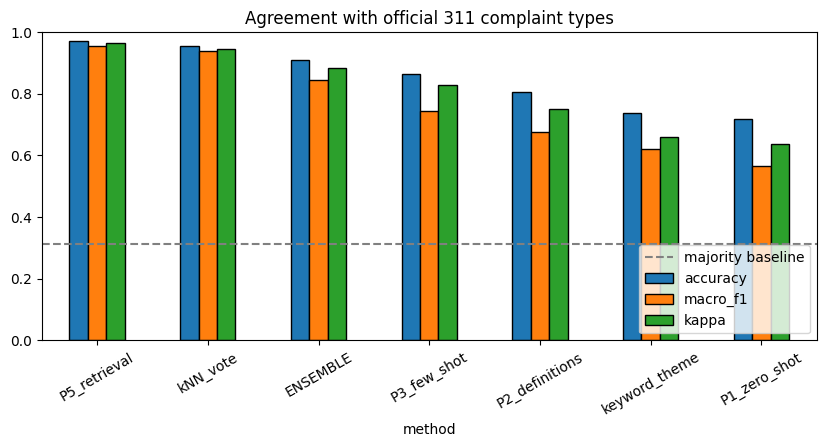

In [16]:
METHODS = ["keyword_theme", "kNN_vote"] + LLM_METHODS
ev = df[df["official_theme"] != "Other"]
y_true = ev["official_theme"]

rows = []
for mth in METHODS:
    y_pred = ev[mth]
    rows.append({"method": mth, "accuracy": accuracy_score(y_true, y_pred),
                 "macro_f1": f1_score(y_true, y_pred, labels=THEMES, average="macro", zero_division=0),
                 "kappa": cohen_kappa_score(y_true, y_pred)})
results = pd.DataFrame(rows).sort_values("accuracy", ascending=False).reset_index(drop=True)
baseline = y_true.value_counts(normalize=True).max()
print(f"Evaluated on {len(ev):,} requests. Majority-class baseline accuracy: {baseline:.1%}")
display(results.round(3))
results.to_csv(DATA_DIR / "evaluation_summary.csv", index=False)

ax = results.set_index("method")[["accuracy", "macro_f1", "kappa"]].plot.bar(figsize=(10, 4), edgecolor="black")
ax.axhline(baseline, ls="--", c="grey", label="majority baseline"); ax.set_ylim(0, 1)
ax.legend(loc="lower right"); ax.set_title("Agreement with official 311 complaint types"); plt.xticks(rotation=30); plt.show()

Best prompt: P5_retrieval 

                              precision    recall  f1-score   support

                       Noise       1.00      0.97      0.99       269
         Housing & Buildings       0.93      1.00      0.96       190
  Streets, Traffic & Parking       0.98      0.99      0.99       311
    Sanitation & Cleanliness       0.97      1.00      0.99        72
  Trees, Parks & Environment       0.98      0.89      0.93        71
Homelessness & Public Safety       1.00      0.84      0.91        55
         Business & Consumer       0.86      0.96      0.91        26

                    accuracy                           0.97       994
                   macro avg       0.96      0.95      0.95       994
                weighted avg       0.97      0.97      0.97       994



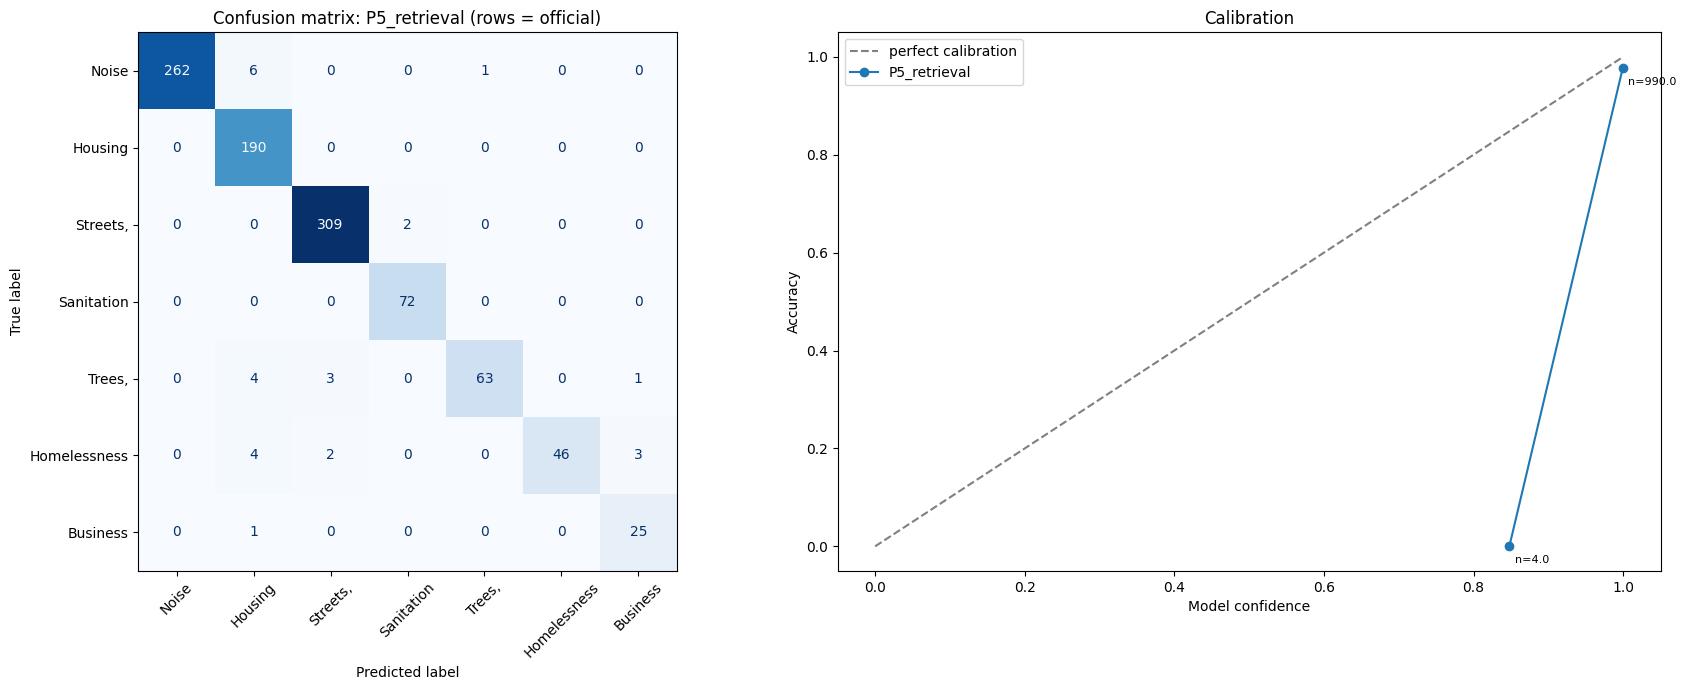

confidence ≥ 0.5: keeps 100% of requests at 97% accuracy
confidence ≥ 0.7: keeps 100% of requests at 97% accuracy
confidence ≥ 0.9: keeps 100% of requests at 98% accuracy


In [17]:
BEST = results.loc[results.method.isin(LLM_METHODS), "method"].iloc[0]
print("Best prompt:", BEST, "\n")
print(classification_report(y_true, ev[BEST], labels=THEMES, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(confusion_matrix(y_true, ev[BEST], labels=THEMES), display_labels=[t.split(" ")[0] for t in THEMES]
                       ).plot(ax=axes[0], cmap="Blues", xticks_rotation=45, colorbar=False)
axes[0].set_title(f"Confusion matrix: {BEST} (rows = official)")

# Calibration: is the model right as often as it is confident?
conf = ev[BEST + "_conf"]; correct = (ev[BEST] == y_true)
bins = pd.cut(conf, [0, .4, .5, .6, .7, .8, .9, 1.0])
calib = pd.DataFrame({"confidence": conf, "correct": correct, "bin": bins}).groupby("bin", observed=True).agg(
    mean_conf=("confidence", "mean"), accuracy=("correct", "mean"), n=("correct", "size"))
axes[1].plot([0, 1], [0, 1], "--", c="grey", label="perfect calibration")
axes[1].plot(calib.mean_conf, calib.accuracy, "o-", label=BEST)
for _, r in calib.iterrows():
    axes[1].annotate(f"n={r.n}", (r.mean_conf, r.accuracy), textcoords="offset points", xytext=(4, -12), fontsize=8)
axes[1].set_xlabel("Model confidence"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Calibration")
axes[1].legend(); plt.tight_layout(); plt.show()

# Abstaining: only accept labels above a confidence threshold
for thr in [0.5, 0.7, 0.9]:
    keep = conf >= thr
    acc = f"{correct[keep].mean():.0%}" if keep.any() else "n/a"
    print(f"confidence ≥ {thr}: keeps {keep.mean():.0%} of requests at {acc} accuracy")

### Review the disagreements by hand
A disagreement is not always a model error: some complaint types are genuinely ambiguous, and our theme map is a choice we made. Read 15 of them and decide who is right.

In [18]:
disagree = ev.loc[ev[BEST] != ev["official_theme"],
                  ["complaint_type", "text", "official_theme", BEST, BEST + "_conf"]]
print(f"{len(disagree)} disagreements out of {len(ev)}")
display(disagree.sort_values(BEST + "_conf", ascending=False).head(15))

27 disagreements out of 994


,complaint_type,text,official_theme,P5_retrieval,P5_retrieval_conf
580,Air Quality,Asbestos Disturbance; location: N/A,"Trees, Parks & Environment",Housing & Buildings,1.000000
668,Overgrown Tree/Branches,Traffic Sign or Signal Blocked; location: Street,"Trees, Parks & Environment","Streets, Traffic & Parking",0.999999
844,Consumer Complaint,Home Improvement Contractor; location: Business,Business & Consumer,Housing & Buildings,0.999989
489,Maintenance or Facility,Grass/Weeds; location: Street/Curbside,"Trees, Parks & Environment","Streets, Traffic & Parking",0.999968
391,Maintenance or Facility,Grass/Weeds; location: Street/Curbside,"Trees, Parks & Environment","Streets, Traffic & Parking",0.999968
214,Water Maintenance,Dirty Water; location: N/A,"Trees, Parks & Environment",Housing & Buildings,0.999959
855,Water Maintenance,Dirty Water; location: N/A,"Trees, Parks & Environment",Housing & Buildings,0.999959
349,Water Maintenance,Dirty Water; location: N/A,"Trees, Parks & Environment",Housing & Buildings,0.999959
245,Noise,Construction; location: Building/Construction Site,Noise,Housing & Buildings,0.999556
10,Noise,Construction; location: Building/Construction Site,Noise,Housing & Buildings,0.999556


### Map the LLM labels
Each request coloured by the theme chosen by the best method. Click a point to compare it with the official theme.

In [19]:
MAP_COL = BEST                       # try "official_theme" to compare
COLORS = dict(zip(THEMES, ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#f781bf"]))
m = folium.Map(location=NYC_CENTER, zoom_start=11, tiles="ESRI.WorldImagery")
for _, r in df.iterrows():
    c = COLORS.get(r[MAP_COL], "#999999")
    folium.CircleMarker([r.latitude, r.longitude], radius=3, color=c, fill=True, fill_color=c, fill_opacity=0.8,
                        popup=folium.Popup(f"<b>{r[MAP_COL]}</b> (official: {r.official_theme})<br>{r.text}",
                                           max_width=300)).add_to(m)
legend = "".join(f"<span style='color:{c}'>●</span> {t}<br>" for t, c in COLORS.items())
m.get_root().html.add_child(folium.Element(
    f"<div style='position:fixed;bottom:20px;left:20px;z-index:999;background:white;padding:6px 10px;"
    f"border:1px solid #999;font-size:12px'><b>{MAP_COL}</b><br>{legend}</div>"))
display(m)
display(pd.crosstab(df["borough"].replace("", "UNSPECIFIED"), df[MAP_COL], normalize="index").round(2))

P5_retrieval,Business & Consumer,Homelessness & Public Safety,Housing & Buildings,Noise,Sanitation & Cleanliness,"Streets, Traffic & Parking","Trees, Parks & Environment"
borough,,,,,,,
BRONX,0.01,0.04,0.31,0.37,0.02,0.21,0.03
BROOKLYN,0.04,0.03,0.19,0.25,0.08,0.34,0.06
MANHATTAN,0.05,0.13,0.20,0.27,0.08,0.19,0.07
QUEENS,0.01,0.01,0.16,0.20,0.08,0.46,0.08
STATEN ISLAND,0.05,0.00,0.11,0.19,0.22,0.30,0.14


In [20]:
# Save everything for later
OUT = DATA_DIR / f"nyc311_classified_{START_DATE}.csv"
df.drop(columns=["created_date"]).assign(created_date=df["created_date"].astype(str)).to_csv(OUT, index=False)
print("Saved:", OUT)
print("Model:", MODEL_NAME if USE_LLM else "offline stand-ins", "| prompts:", RUN_PROMPTS, "| seed:", SEED)

Saved: /content/drive/MyDrive/Colab Notebooks/GenAI_Spatial_Workshop/nyc311_classified_2026-09-01.csv
Model: google/gemma-4-E2B-it | prompts: ['P1_zero_shot', 'P2_definitions', 'P3_few_shot', 'P5_retrieval'] | seed: 42


# Part 6 — Next Steps
1. Write a new prompt `P6_...` in `PROMPTS`, add it to `RUN_PROMPTS` and rerun Parts 4–5. Can you beat the best prompt?
2. Switch `MODEL_NAME` to `google/gemma-4-E4B-it` (with `LOAD_IN_4BIT = True`). How do accuracy, calibration and runtime change?
3. In the map at the end of Part 5, set `MAP_COL = "official_theme"`. Where do the LLM and official labels disagree?
4. Run all five prompts with `RUN_PROMPTS = list(PROMPTS)`. Does adding the borough and time of day (`P4_geo_context`) help?
